# 05 全局分层查询集与多城市配对检索

本 notebook 从 03 已建立的约 4.7 万个多城市候选街区中重新选择正式查询，不再以 Luxembourg 为唯一查询来源。选择和检索分成两个阶段：

1. 在全体样本的屋顶指标百分位空间中定义五种查询情景；
2. 每类选择 10 个查询，优先接近类别目标，同时保持总体形态多样，并限制单个城市在一类中最多占 3 个；
3. 冻结查询集后，再分别运行 M1 与 M2 的前 5 名检索。

本流程只读 03 的 parquet 文件，不重算几何指标，也不写入数据库。

In [1]:
from __future__ import annotations

import importlib
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

def find_notebook_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'global_query_selection.py').is_file():
        return current
    for parent in (current, *current.parents):
        candidate = parent / 'casebase' / 'lod2_roof_retrieval_experiment'
        if (candidate / 'global_query_selection.py').is_file():
            return candidate
    raise FileNotFoundError('未找到 lod2_roof_retrieval_experiment 目录。')

NOTEBOOK_DIR = find_notebook_dir()
os.chdir(NOTEBOOK_DIR)
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import block_metrics as bm
import global_query_selection as gqs
import multicity_pipeline as mp
import multicity_visualization as mviz
import retrieval as rt

for module in (gqs, mviz, rt):
    importlib.reload(module)

## 1. 固定参数

五类目标定义在全体样本的屋顶指标百分位空间中。`GENERAL_CENTRAL_QUANTILE=0.98` 仅把总体形态最极端的 2% 排除出查询端；这些街区仍保留在候选库中。城市上限只是防止某个类别被单一数据源垄断，不要求各城市平均入选。

In [2]:
BASE_SEED = 20260910
QUERIES_PER_CATEGORY = 10
MAX_PER_CITY_PER_CATEGORY = 3
MIN_GENERAL_SEPARATION = 0.55
GENERAL_CENTRAL_QUANTILE = 0.98
POOL_SIZE = 50
TOP_K = 5
PRIMARY_LAMBDA = 0.35

SOURCE_DIR = NOTEBOOK_DIR / 'outputs' / 'multicity'
SOURCE_POOL_PATH = SOURCE_DIR / 'multicity_block_metrics.parquet'
OUTPUT_DIR = SOURCE_DIR / 'global_queries'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RUN_CONFIG = {
    'base_seed': BASE_SEED,
    'queries_per_category': QUERIES_PER_CATEGORY,
    'max_per_city_per_category': MAX_PER_CITY_PER_CATEGORY,
    'min_general_separation': MIN_GENERAL_SEPARATION,
    'general_central_quantile': GENERAL_CENTRAL_QUANTILE,
    'pool_size': POOL_SIZE,
    'top_k': TOP_K,
    'primary_lambda': PRIMARY_LAMBDA,
    'm1_features': mp.FROZEN_M1_FEATURES,
    'roof_features': list(bm.ROOF_FEATURES),
}
pd.Series(RUN_CONFIG)

base_seed                                                             20260910
queries_per_category                                                        10
max_per_city_per_category                                                    3
min_general_separation                                                    0.55
general_central_quantile                                                  0.98
pool_size                                                                   50
top_k                                                                        5
primary_lambda                                                            0.35
m1_features                  [log_block_area, compactness, elongation, bcr,...
roof_features                [roof_mean_slope, roof_relief_ratio_median, bu...
dtype: object

## 2. 读取冻结的多城市样本池

这里使用 03 保存的最终 `multicity_block_metrics.parquet`。查询和候选来自同一张表，但检索函数会按“城市 + 街区 ID”排除查询自身。

In [3]:
if not SOURCE_POOL_PATH.is_file():
    raise FileNotFoundError(f'缺少 03 的最终样本池：{SOURCE_POOL_PATH}')

multicity_blocks = pd.read_parquet(SOURCE_POOL_PATH)
required_columns = {
    'city', 'block_id', *mp.FROZEN_M1_FEATURES, *bm.ROOF_FEATURES
}
missing_columns = sorted(required_columns - set(multicity_blocks.columns))
if missing_columns:
    raise ValueError('样本池缺少字段：' + ', '.join(missing_columns))
if multicity_blocks.duplicated(['city', 'block_id']).any():
    raise ValueError('样本池存在重复的 city/block_id。')

pd.Series({
    'blocks': len(multicity_blocks),
    'cities': multicity_blocks['city'].nunique(),
    'complete_roof_rows': int(multicity_blocks[list(bm.ROOF_FEATURES)].notna().all(axis=1).sum()),
})

blocks                47323
cities                   19
complete_roof_rows    47323
dtype: int64

## 3. 查看五类全局目标

数值表示全体 4.7 万个样本中的百分位位置，而不是某个城市内部的百分位。高坡度、高起伏和高混合度分别只提高一个目标维度，避免把三种屋顶信息混成同一个“复杂度”。

In [4]:
archetype_rows = []
for archetype in gqs.DEFAULT_ROOF_ARCHETYPES:
    row = {'query_category': archetype.name, 'label': archetype.label}
    row.update({
        f'{feature}_target_percentile': target
        for feature, target in zip(bm.ROOF_FEATURES, archetype.targets)
    })
    archetype_rows.append(row)
archetype_table = pd.DataFrame(archetype_rows)
display(archetype_table.style.format({column: '{:.2f}' for column in archetype_table if column.endswith('_percentile')}))

,query_category,label,roof_mean_slope_target_percentile,roof_relief_ratio_median_target_percentile,building_roof_slope_sd_target_percentile
0,near_flat,Near-flat,0.10,0.10,0.10
1,typical,Typical,0.50,0.50,0.50
2,steep,Steep,0.90,0.50,0.50
3,high_relief,High relief,0.50,0.90,0.50
4,heterogeneous,Heterogeneous,0.50,0.50,0.90


## 4. 选择并冻结约 50 个正式查询

算法首先按类别目标距离从近到远考察街区；在目标接近的前提下，要求新查询与已选查询在 M1 总体形态空间中保持最小距离。若一类中候选过密，距离阈值逐级放宽，但城市上限和跨类别不重复始终保留。

In [5]:
formal_queries = gqs.build_global_query_set(
    multicity_blocks,
    general_features=mp.FROZEN_M1_FEATURES,
    roof_features=bm.ROOF_FEATURES,
    queries_per_category=QUERIES_PER_CATEGORY,
    max_per_city_per_category=MAX_PER_CITY_PER_CATEGORY,
    min_general_separation=MIN_GENERAL_SEPARATION,
    general_central_quantile=GENERAL_CENTRAL_QUANTILE,
    seed=BASE_SEED,
)

query_columns = [
    'query_category', 'query_category_label', 'selection_rank',
    'city', 'block_id', 'target_distance',
    'general_central_distance', 'general_separation_at_selection',
    *bm.ROOF_FEATURES,
    *[f'{feature}_percentile' for feature in bm.ROOF_FEATURES],
]
display(formal_queries[query_columns])

,query_category,query_category_label,selection_rank,city,block_id,target_distance,general_central_distance,general_separation_at_selection,roof_mean_slope,roof_relief_ratio_median,building_roof_slope_sd,roof_mean_slope_percentile,roof_relief_ratio_median_percentile,building_roof_slope_sd_percentile
0,near_flat,Near-flat,1,newyork,US_NY_034226,0.029542,0.371498,NaN,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
1,near_flat,Near-flat,2,prague,CZ_PR_006074,0.029542,1.126331,1.272490,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
2,near_flat,Near-flat,3,prague,CZ_PR_002233,0.029542,0.827828,1.007993,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
3,near_flat,Near-flat,4,prague,CZ_PR_000902,0.029542,1.164362,1.018212,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
4,near_flat,Near-flat,5,dresden,DE_DD_001139,0.029542,1.570230,1.167113,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
5,near_flat,Near-flat,6,newyork,US_NY_020286,0.029542,1.371778,1.189988,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
6,near_flat,Near-flat,7,newyork,US_NY_001068,0.029542,0.877087,0.632436,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
7,near_flat,Near-flat,8,hamburg,DE_HH_000946,0.029542,2.659861,1.378616,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
8,near_flat,Near-flat,9,munich,DE_MU_004563,0.029542,0.838620,0.912148,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086
9,near_flat,Near-flat,10,vienna,AT_VI_005451,0.029542,0.874843,1.010223,0.000000,0.000000,0.000000,0.064345,0.122604,0.071086


## 5. 查询集覆盖诊断

这里检查每类是否恰好有 10 个查询、覆盖多少城市、是否触及每类每城最多 3 个的上限，以及实际查询与类别目标相距多远。城市分布只作为集中度审计，不作为实验分组。

,query_category,query_category_label,query_count,city_count,max_city_count,median_target_distance,max_target_distance,median_general_central_distance
0,near_flat,Near-flat,10,6,3,0.029542,0.029542,1.001709
1,typical,Typical,10,6,2,0.012163,0.018009,0.633709
2,steep,Steep,10,6,3,0.024600,0.041137,0.931546
3,high_relief,High relief,10,5,3,0.020495,0.025626,0.826307
4,heterogeneous,Heterogeneous,10,6,3,0.020133,0.033011,1.144646


query_category,heterogeneous,high_relief,near_flat,steep,typical
city,,,,,
amsterdam,0,0,0,0,1
berlin,3,0,0,2,0
bern,0,1,0,0,0
dresden,1,0,1,0,2
hamburg,2,0,1,1,0
linz,0,0,0,0,1
luxembourg,0,2,0,1,0
munich,1,1,1,0,2
newyork,0,0,3,0,0


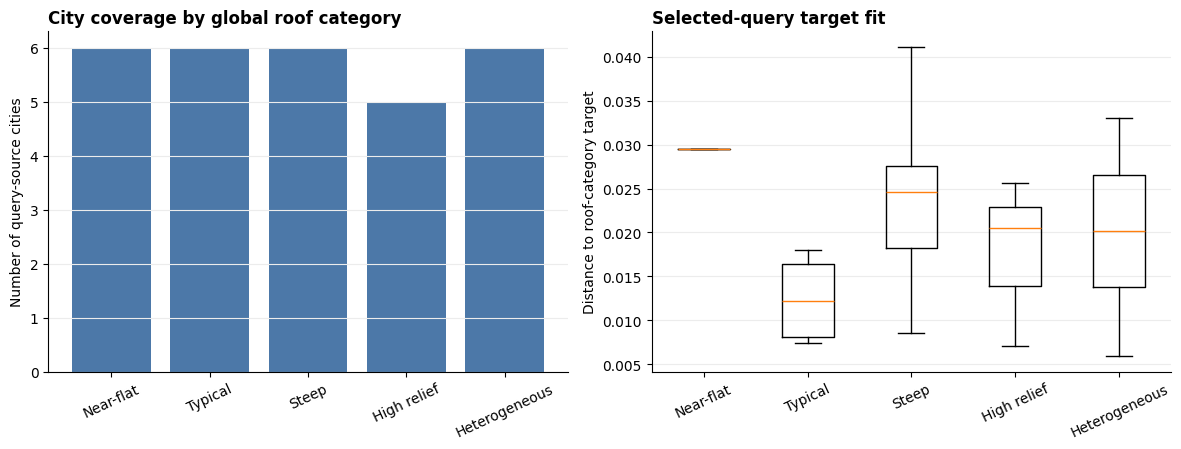

In [6]:
query_selection_summary = gqs.summarize_global_query_set(formal_queries)
category_city_counts = (
    formal_queries.groupby(['query_category', 'city']).size()
    .rename('query_count').reset_index()
)
display(query_selection_summary)
display(category_city_counts.pivot(index='city', columns='query_category', values='query_count').fillna(0).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].bar(query_selection_summary['query_category_label'], query_selection_summary['city_count'], color='#4C78A8')
axes[0].set_ylabel('Number of query-source cities')
axes[0].set_title('City coverage by global roof category', loc='left', fontweight='bold')
axes[0].tick_params(axis='x', rotation=25)
axes[1].boxplot(
    [group['target_distance'] for _, group in formal_queries.groupby('query_category', sort=False)],
    tick_labels=formal_queries['query_category_label'].drop_duplicates().tolist(),
)
axes[1].set_ylabel('Distance to roof-category target')
axes[1].set_title('Selected-query target fit', loc='left', fontweight='bold')
axes[1].tick_params(axis='x', rotation=25)
for axis in axes:
    axis.grid(axis='y', color='#ECECEC')
    axis.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
selection_figure_path = OUTPUT_DIR / 'query_selection_diagnostics.png'
fig.savefig(selection_figure_path, dpi=240, bbox_inches='tight', facecolor='white')
plt.show()

## 6. 在检索前保存查询集与参数

这一保存顺序用于明确：查询类别由形态指标预先确定，而不是看到 M1/M2 结果后再调整。重复运行使用相同数据与参数会得到完全相同的查询集。

In [7]:
formal_query_csv = OUTPUT_DIR / 'global_formal_queries.csv'
formal_query_parquet = OUTPUT_DIR / 'global_formal_queries.parquet'
formal_queries.to_csv(formal_query_csv, index=False, encoding='utf-8-sig')
formal_queries.to_parquet(formal_query_parquet, index=False)
query_selection_summary.to_csv(OUTPUT_DIR / 'query_selection_summary.csv', index=False, encoding='utf-8-sig')
category_city_counts.to_csv(OUTPUT_DIR / 'query_category_city_counts.csv', index=False, encoding='utf-8-sig')
with (OUTPUT_DIR / 'global_query_config.json').open('w', encoding='utf-8') as file:
    json.dump(RUN_CONFIG, file, ensure_ascii=False, indent=2)
print(f'已在检索前冻结 {len(formal_queries)} 个查询：{formal_query_csv}')

已在检索前冻结 50 个查询：E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\global_formal_queries.csv


## 7. 运行 M1/M2 配对检索

M1先按11项总体形态指标从全部候选中建立前50名共享候选池；M2只在同一个候选池中加入三项屋顶指标，以固定权重 `λ=0.35` 重新排序。两种方法都返回前5名。

In [8]:
general_scaler = rt.RobustFeatureScaler.fit(multicity_blocks, mp.FROZEN_M1_FEATURES)
roof_scaler = rt.RobustFeatureScaler.fit(multicity_blocks, bm.ROOF_FEATURES)
retrieval_parts = []
for query_index, query in enumerate(formal_queries.itertuples(index=False), start=1):
    result = rt.retrieve_for_query(
        multicity_blocks,
        query_id=str(query.block_id),
        query_city=str(query.city),
        general_features=mp.FROZEN_M1_FEATURES,
        roof_features=bm.ROOF_FEATURES,
        pool_size=POOL_SIZE,
        top_k=TOP_K,
        lambda_values=[PRIMARY_LAMBDA],
        general_scaler=general_scaler,
        roof_scaler=roof_scaler,
    )
    result['query_category'] = query.query_category
    result['query_category_label'] = query.query_category_label
    result['query_selection_rank'] = int(query.selection_rank)
    result['query_target_distance'] = float(query.target_distance)
    retrieval_parts.append(result)
    if query_index % 5 == 0 or query_index == len(formal_queries):
        print(f'[{query_index:02d}/{len(formal_queries):02d}] paired retrieval complete')

global_retrieval_results = pd.concat(retrieval_parts, ignore_index=True)
expected_rows = len(formal_queries) * 2 * TOP_K
if len(global_retrieval_results) != expected_rows:
    raise RuntimeError(f'检索结果应为 {expected_rows} 行，实际为 {len(global_retrieval_results)} 行。')
display(global_retrieval_results.head(20))

[05/50] paired retrieval complete
[10/50] paired retrieval complete
[15/50] paired retrieval complete
[20/50] paired retrieval complete
[25/50] paired retrieval complete
[30/50] paired retrieval complete
[35/50] paired retrieval complete
[40/50] paired retrieval complete
[45/50] paired retrieval complete
[50/50] paired retrieval complete


,query_id,method,lambda_value,rank,candidate_id,d_general,d_roof,d_combined,pool_size,general_pool_rank,query_city,candidate_city,same_city,query_category,query_category_label,query_selection_rank,query_target_distance
0,US_NY_034226,M1,0.00,1,US_NY_029468,0.069347,0.000000,0.069347,50,1,newyork,newyork,True,near_flat,Near-flat,1,0.029542
1,US_NY_034226,M1,0.00,2,US_NY_031925,0.069817,0.000000,0.069817,50,2,newyork,newyork,True,near_flat,Near-flat,1,0.029542
2,US_NY_034226,M1,0.00,3,US_NY_034400,0.076781,0.000000,0.076781,50,3,newyork,newyork,True,near_flat,Near-flat,1,0.029542
3,US_NY_034226,M1,0.00,4,US_NY_034687,0.090324,0.000000,0.090324,50,4,newyork,newyork,True,near_flat,Near-flat,1,0.029542
4,US_NY_034226,M1,0.00,5,US_NY_034187,0.091505,0.000000,0.091505,50,5,newyork,newyork,True,near_flat,Near-flat,1,0.029542
5,US_NY_034226,M2,0.35,1,US_NY_029468,0.069347,0.000000,0.045075,50,1,newyork,newyork,True,near_flat,Near-flat,1,0.029542
6,US_NY_034226,M2,0.35,2,US_NY_031925,0.069817,0.000000,0.045381,50,2,newyork,newyork,True,near_flat,Near-flat,1,0.029542
7,US_NY_034226,M2,0.35,3,US_NY_034400,0.076781,0.000000,0.049908,50,3,newyork,newyork,True,near_flat,Near-flat,1,0.029542
8,US_NY_034226,M2,0.35,4,US_NY_034687,0.090324,0.000000,0.058711,50,4,newyork,newyork,True,near_flat,Near-flat,1,0.029542
9,US_NY_034226,M2,0.35,5,US_NY_034187,0.091505,0.000000,0.059478,50,5,newyork,newyork,True,near_flat,Near-flat,1,0.029542


## 8. 汇总五类查询的初步变化

`roof_gain > 0` 表示M2的屋顶距离更小；`general_cost > 0` 表示M2为此牺牲了一部分总体形态相似性。这只是基于检索距离的诊断，最终仍需结合04生成的案例图解释。

In [9]:
query_diagnostics = mviz.build_query_gain_cost(global_retrieval_results, top_k=TOP_K)
category_diagnostics = (
    query_diagnostics.groupby(['query_category', 'query_category_label'], sort=False, as_index=False)
    .agg(
        queries=('query_id', 'size'),
        mean_roof_gain=('roof_gain', 'mean'),
        median_roof_gain=('roof_gain', 'median'),
        mean_general_cost=('general_cost', 'mean'),
        median_general_cost=('general_cost', 'median'),
        mean_top5_overlap=('top_k_overlap', 'mean'),
    )
)
display(category_diagnostics.style.format({
    'mean_roof_gain': '{:.3f}', 'median_roof_gain': '{:.3f}',
    'mean_general_cost': '{:.3f}', 'median_general_cost': '{:.3f}',
    'mean_top5_overlap': '{:.2f}',
}))

,query_category,query_category_label,queries,mean_roof_gain,median_roof_gain,mean_general_cost,median_general_cost,mean_top5_overlap
0,near_flat,Near-flat,10,0.614,0.668,0.068,0.057,1.90
1,typical,Typical,10,0.200,0.199,0.036,0.030,2.00
2,steep,Steep,10,0.417,0.451,0.050,0.052,1.70
3,high_relief,High relief,10,0.222,0.186,0.033,0.033,1.90
4,heterogeneous,Heterogeneous,10,0.273,0.241,0.048,0.044,1.30


## 9. 保存检索结果，供04可视化

04 notebook 将读取本目录中的正式查询和检索结果，并默认从每类中选择一个接近该类总体表现的代表案例。

In [10]:
retrieval_csv = OUTPUT_DIR / 'global_retrieval_results.csv'
global_retrieval_results.to_csv(retrieval_csv, index=False, encoding='utf-8-sig')
global_retrieval_results.to_parquet(OUTPUT_DIR / 'global_retrieval_results.parquet', index=False)
query_diagnostics.to_csv(OUTPUT_DIR / 'global_query_diagnostics.csv', index=False, encoding='utf-8-sig')
category_diagnostics.to_csv(OUTPUT_DIR / 'global_category_diagnostics.csv', index=False, encoding='utf-8-sig')
print(f'已保存 {len(formal_queries)} 个查询和 {len(global_retrieval_results)} 条配对结果。')
print(f'下一步请重新运行 04：{retrieval_csv}')

已保存 50 个查询和 500 条配对结果。
下一步请重新运行 04：E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\global_retrieval_results.csv
